# Inference for Regression: Boostrapping 

This lecture is based on Lecture 33: Regression Inference. 

**Helpful Resource:**
- [Python Reference](http://data8.org/sp22/python-reference.html): Cheat sheet of helpful array & table methods used in Data 8!

**Recommended Readings**: 
- [Regression Inference](https://inferentialthinking.com/chapters/16/Inference_for_Regression.html)


In [2]:
from datascience import *
%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
import numpy as np
from math import ceil

In [3]:
# Ignore this code; it's graphics for demonstrating the regression model
def draw_and_compare(true_slope, true_int, sample_size):
    x = np.random.normal(50, 5, sample_size)
    xlims = np.array([np.min(x), np.max(x)])
    errors = np.random.normal(0, 6, sample_size)
    y = (true_slope * x + true_int) + errors
    sample = Table().with_columns('x', x, 'y', y)

    sample.scatter('x', 'y')
    plots.plot(xlims, true_slope*xlims + true_int, lw=2, color='green')
    plots.title('True Line, and Points Created')

    sample.scatter('x', 'y')
    plots.title('What We Get to See')

    sample.scatter('x', 'y', fit_line=True)
    plots.title('Regression Line: Estimate of True Line')

    sample.scatter('x', 'y', fit_line=True)
    plots.plot(xlims, true_slope*xlims + true_int, lw=2, color='green')
    plots.title("Regression Line and True Line")

In [4]:
def standard_units(numbers_array):
    "Convert any array of numbers to standard units."
    return (numbers_array - np.mean(numbers_array))/np.std(numbers_array)  

def correlation(table, label_x, label_y):
    return np.mean(standard_units(table.column(label_x))*standard_units(table.column(label_y)))

def slope(table, label_x, label_y):
    r = correlation(table, label_x, label_y)
    return r*np.std(table.column(label_y))/np.std(table.column(label_x))

def intercept(table, label_x, label_y):
    return np.mean(table.column(label_y)) - slope(table, label_x, label_y)*np.mean(table.column(label_x))

def fitted_values(table, x, y):
    """Return an array of the regression estimates at all the x values"""
    a = slope(table, x, y)
    b = intercept(table, x, y)
    return a*table.column(x) + b  


### Inference and Prediction

We normally don't have a dataset for an entire population. We, as always only have a sample from a larger population. So we probably have questions of:

- If in the sample we found a linear relation between the two variables, would the same be true for the population?
- Would it be exactly the same linear relation?
- Could we predict the response of a new individual who is not in our sample?

To answer these questions, we need to develop a regression model.

### Regression Model

**"Sets of assumptions about randomness in roughly linear scatter plots are called regression models."**

That means we believe that there is a straight line running across the graph to signal that there is a linear relationship between the variables (x and y). But because of random noise, the straight line is bluried in the scatter plots. So our job is to develop sets of assumptions to fish the straight line out of the scatter plot, and that is regression model.

Random noise is something unpredictable, accidential, has no pattern, no defined meaning and no relation to the variables that we are trying to compare. Simply put, random noise is a distraction.

In the graph: _True line_ is the signal of having a straight line.

<img src="regression-model-a.png" alt="regression model" width=450/>
<img src="regression-model-b.png" alt="regression model" width=450/>

This tried to illustrate that if we have a large sample, then the regression line is a good approximation to the true line.

### Recap: Regression Equation

The formulas for computing the slope and intercept are both based on the correlation coefficient $r$ computed above: 

$$m = r \cdot \frac{SD_y}{SD_x}$$

$$b = \bar{y} - m\bar{x}$$

where $\bar{y}$ and $\bar{x}$ are the means of x and y values, respectively. $SD$ is standard deviation. $m$ is the slope and $b$ is the intercept of the regression line.

So, when we predict $\bar{y}$ based on $\bar{x}$,

$$\bar{y} = m\bar{x} + b$$

We need three function to calculate the $r$ (correlation), the $m$ (slope) and the $b$ (intercept).

### Inference for the True Slope

#### Example: Blood Sugar (glucose) Levels, Age and Metabolism

As a patient ages, baseline metabolic efficiency changes that means the fasting blood glucose level measured in mg/dL increases as we age. This is a clear and obvious positive clinical signal for many diseases. But the signal (linear relationship of ages and fasting blood sugar level) may be blurred in random noise (distraction), like individual diet, genetics and activity levels.

Like say, we have:

**Null hypothesis:** there is no linear relationship between age and fasting blood glucose level.

**Alternative hypothesis:** there is linear relationship between age and fasting blood glucose level.

In [5]:
# load the dataset to a table
metabolic = Table.read_table('metabolic.csv')
metabolic.show(3)

age,glucose
59,116.292
72,150.692
49,140.847


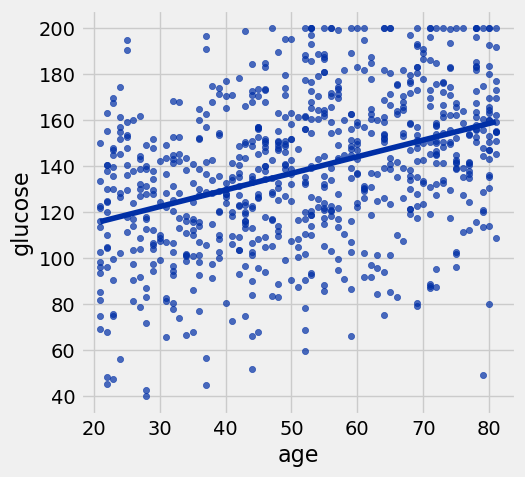

In [6]:
# visualize the dataset, 
#   fit_line=True to overlay the least squares linear regression line
metabolic.scatter('age', 'glucose', fit_line=True)

In [7]:
# check the correlation
correlation(metabolic, 'age', 'glucose')

0.38152310882219642

In [8]:
# check the slope
slope(metabolic, 'age', 'glucose')

0.72322410717022334

#### Prediction at a Given Value of x

In [9]:
def prediction_at(table, x, y, x_predictor):
    ''' x_predictor - the x value for which we want to predict y '''
    m = slope(table, x, y)
    b = intercept(table, x, y)
    return m * x_predictor + b

In [10]:
prediction_at(metabolic, 'age', 'glucose', 48)

135.39386954091609

at_age: 55 glucose: 140.45643829110765


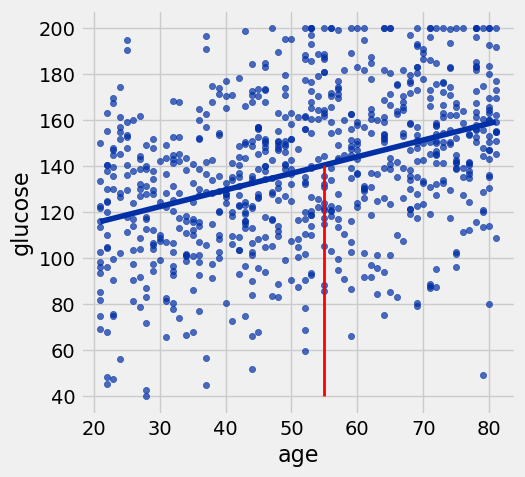

In [11]:
at_age = 55
predict_glucose_at_age = prediction_at(metabolic, 'age', 'glucose', at_age)
metabolic.scatter('age', 'glucose', fit_line=True)
plots.plot([at_age, at_age], [40, predict_glucose_at_age], color='red', lw=2);
print(f"at_age: {at_age} glucose: {predict_glucose_at_age}")

#### Bootstrapping the Scatter Plot

Let's bootstrap the original sample a few times to observe the results.

In [12]:
resampled_1 = metabolic.sample()
resampled_2 = metabolic.sample()
resampled_3 = metabolic.sample()
resampled_4 = metabolic.sample()
resampled_5 = metabolic.sample()

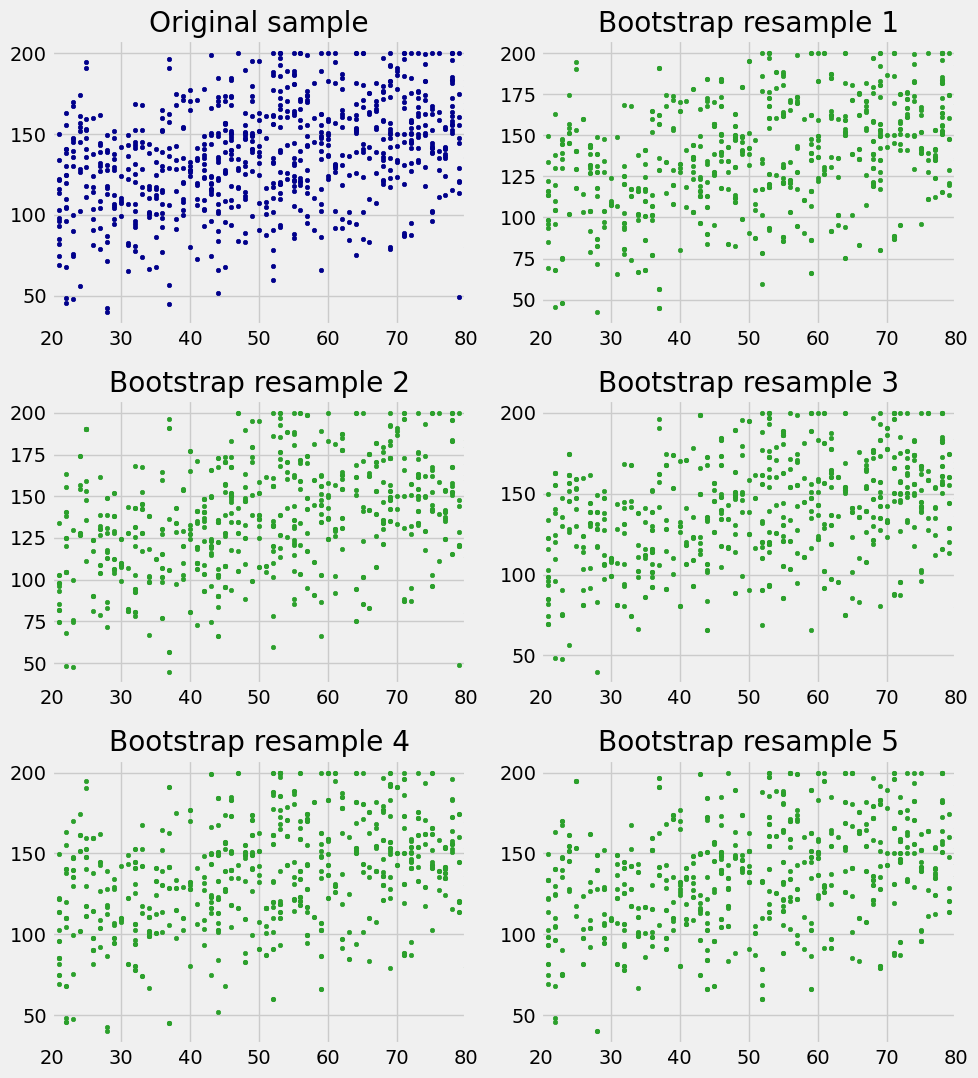

In [13]:
# Let's understand the figure that comes out.

plots.figure(figsize=(10, 11))
plots.subplot(3, 2, 1)
plots.scatter(metabolic.column('age'), metabolic.column('glucose'), s=10, color='darkblue')
plots.xlim([20, 80])
plots.title('Original sample')

plots.subplot(3, 2, 2)
plots.scatter(resampled_1.column('age'), resampled_1.column('glucose'), s=10, color='tab:green')
plots.xlim([20, 80])
plots.title('Bootstrap resample 1')

plots.subplot(3, 2, 3)
plots.scatter(resampled_2.column('age'), resampled_2.column('glucose'), s=10, color='tab:green')
plots.xlim([20, 80])
plots.title('Bootstrap resample 2')

plots.subplot(3, 2, 4)
plots.scatter(resampled_3.column('age'), resampled_3.column('glucose'), s=10, color='tab:green')
plots.xlim([20, 80])
plots.title('Bootstrap resample 3')

plots.subplot(3, 2, 5)
plots.scatter(resampled_4.column('age'), resampled_4.column('glucose'), s=10, color='tab:green')
plots.xlim([20, 80])
plots.title('Bootstrap resample 4')

plots.subplot(3, 2, 6)
plots.scatter(resampled_5.column('age'), resampled_5.column('glucose'), s=10, color='tab:green')
plots.xlim([20, 80])
plots.title('Bootstrap resample 5')

plots.tight_layout()

#### Make Prediction on the Bootstrapped Samples

In [14]:
at_age = 63
predict_y_glucose_resample_1 = prediction_at(resampled_1, 'age', 'glucose', at_age)
predict_y_glucose_resample_2 = prediction_at(resampled_2, 'age', 'glucose', at_age)
predict_y_glucose_resample_3 = prediction_at(resampled_3, 'age', 'glucose', at_age)
print(f"resample_1 at_age: {at_age} glucose: {predict_y_glucose_resample_1}")
print(f"resample_2 at_age: {at_age} glucose: {predict_y_glucose_resample_2}")
print(f"resample_3 at_age: {at_age} glucose: {predict_y_glucose_resample_3}")

resample_1 at_age: 63 glucose: 145.08805699874375
resample_2 at_age: 63 glucose: 146.33887125589354
resample_3 at_age: 63 glucose: 148.39337211773685


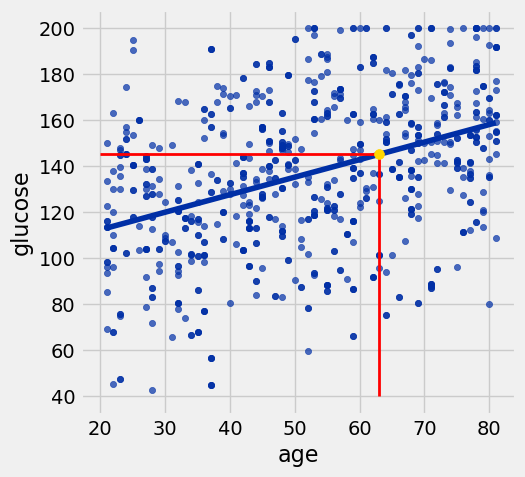

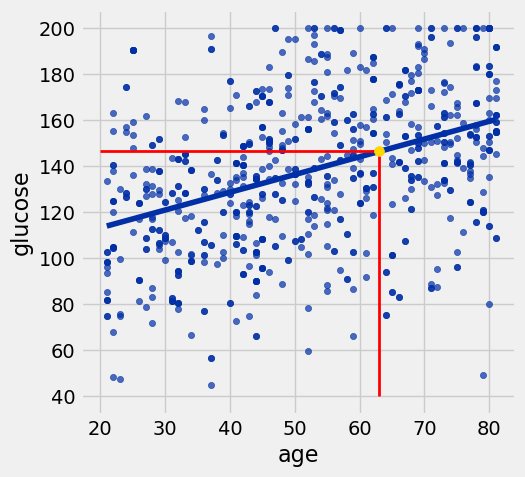

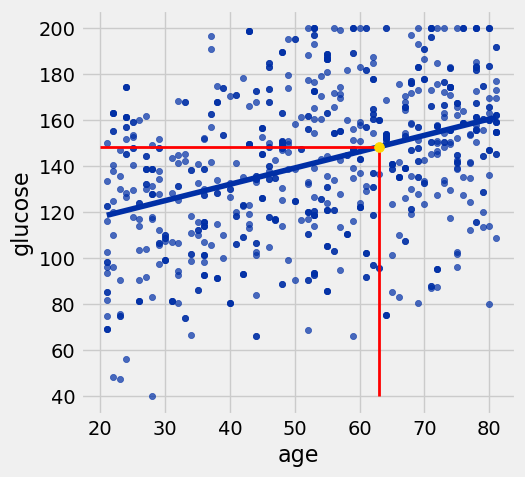

In [15]:
# check out their scatter plots
resampled_1.scatter('age', 'glucose', fit_line=True)
plots.plot([at_age, at_age], [40, predict_y_glucose_resample_1], color='red', lw=2);
plots.plot([20, at_age], [predict_y_glucose_resample_1, predict_y_glucose_resample_1], color='red', lw=2);
plots.scatter(at_age, predict_y_glucose_resample_1, color='gold', s=50, zorder=3);

resampled_2.scatter('age', 'glucose', fit_line=True)
plots.plot([at_age, at_age], [40, predict_y_glucose_resample_2], color='red', lw=2);
plots.plot([20, at_age], [predict_y_glucose_resample_2, predict_y_glucose_resample_2], color='red', lw=2);
plots.scatter(at_age, predict_y_glucose_resample_2, color='gold', s=50, zorder=3);

resampled_3.scatter('age', 'glucose', fit_line=True)
plots.plot([at_age, at_age], [40, predict_y_glucose_resample_3], color='red', lw=2);
plots.plot([20, at_age], [predict_y_glucose_resample_3, predict_y_glucose_resample_3], color='red', lw=2);
plots.scatter(at_age, predict_y_glucose_resample_3, color='gold', s=50, zorder=3);

#### Estimating the True Slope

All regression lines have a slope and that affects the position of the regression lines on a scatter plot. By estimating the true slope, we can develop a confidence interval to estimate regression lines.

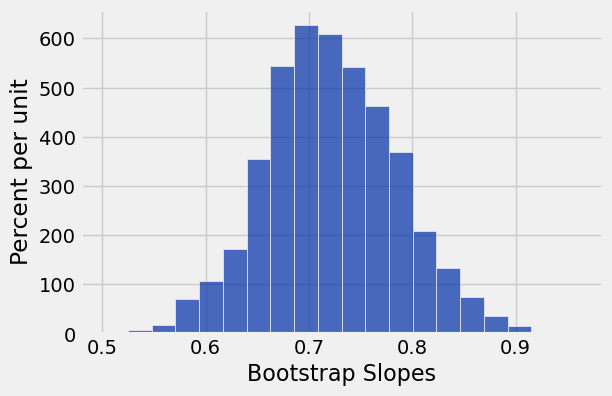

In [16]:
# bootstrap simulation
slopes = make_array()
for i in np.arange(2500):
    bootstrap_sample = metabolic.sample()
    bootstrap_slope = slope(bootstrap_sample, 'age', 'glucose')
    slopes = np.append(slopes, bootstrap_slope)

bootstapped_slope = Table().with_column('Bootstrap Slopes', slopes)
bootstapped_slope.hist(bins=20)

#### Confidence Interval for the Slope of the True Line

As always, we take the "middle 95%" confidence interval.

In [17]:
left = percentile(2.5, slopes)
right = percentile(97.5, slopes)
left, right

(0.59782827476793454, 0.84918578181496018)

Slope of regression line: 0.72322410717
Approximate 95%-confidence interval for the true slope:
0.597828274768 0.849185781815


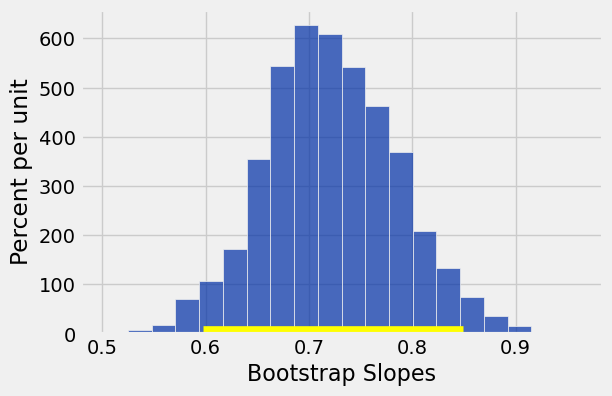

In [18]:
observed_slope = slope(metabolic, 'age', 'glucose')
bootstapped_slope.hist(bins=20)
plots.plot(make_array(left, right), make_array(0, 0), color='yellow', lw=12);
print('Slope of regression line:', observed_slope)
print('Approximate 95%-confidence interval for the true slope:')
print(left, right)

An approximate 95% confidence interval for the true slope is that for each year we age, our fasting blood glucose level increases from 0.59 mg/dL to 0.84 mg/dL. In other words, older we get, slower metabolism we have.

### Function to Bootstrap the Slope

In [19]:
def bootstrap_slope_simulation(table, x, y, repetitions):
    
    # For each repetition:
    # Bootstrap the scatter, get the slope of the regression line,
    # augment the list of generated slopes
    slopes = make_array()
    for i in np.arange(repetitions):
        bootstrap_sample = table.sample()
        bootstrap_slope = slope(bootstrap_sample, x, y)
        slopes = np.append(slopes, bootstrap_slope)
    
    # Find the endpoints of the 95% confidence interval for the true slope
    left = percentile(2.5, slopes)
    right = percentile(97.5, slopes)
    
    # Slope of the regression line from the original sample
    observed_slope = slope(table, x, y)
    
    # Display results
    Table().with_column('Bootstrap Slopes', slopes).hist(bins=20)
    plots.plot(make_array(left, right), make_array(0, 0), color='yellow', lw=12);
    print('Slope of regression line:', observed_slope)
    print('Approximate 95%-confidence interval for the true slope:')
    print(left, right)

Slope of regression line: 0.72322410717
Approximate 95%-confidence interval for the true slope:
0.603651898038 0.843152550509


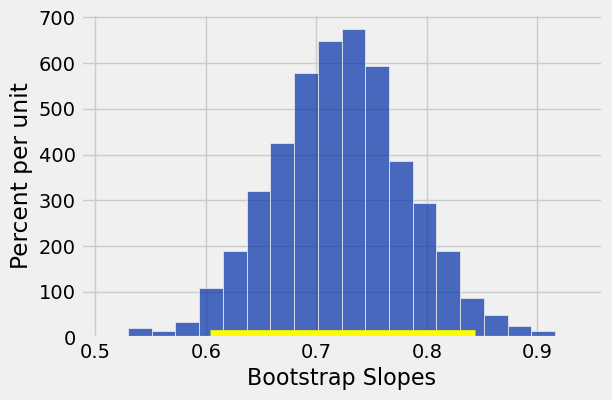

In [20]:
bootstrap_slope_simulation(metabolic, 'age', 'glucose', 2500)

#### Another Example on Confidence Interval for the Slope of the True Line

In [21]:
hybrid = Table.read_table('hybrid.csv')
hybrid.show(2)

vehicle,year,msrp,acceleration,mpg,class
Prius (1st Gen),1997,24509.7,7.46,41.26,Compact
Tino,2000,35355,8.2,54.1,Compact


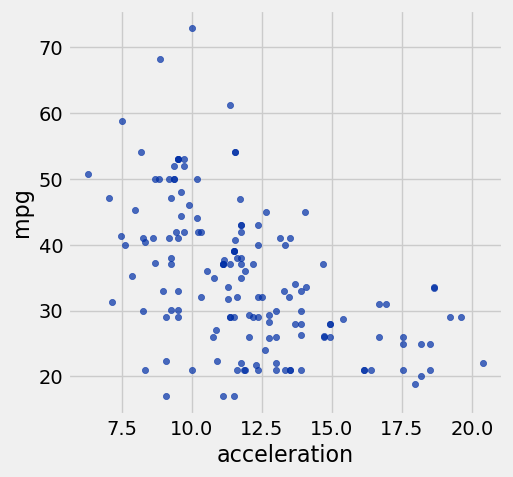

In [22]:
hybrid.scatter('acceleration', 'mpg')

Slope of regression line: -1.88858652379
Approximate 95%-confidence interval for the true slope:
-2.34783754611 -1.45798402774


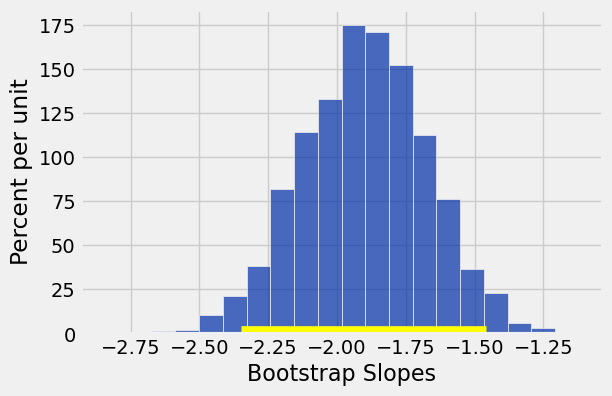

In [23]:
bootstrap_slope_simulation(hybrid, 'acceleration', 'mpg', 5000)

An approximate 95% confidence interval for the true slope is that each additional unit of acceleration capacity reduces fuel efficiency down by 1.45 MPG to 2.34 MPG.

### Could the True Slope Be 0?

We need to develop confidence interval to determine.

Let's start with estabishing hypotheses.

**Null Hypothesis:** The slope of the true line is 0 (there is no correlation).

**Alternative Hypothesis:** The slope of the true line is not 0 (there is correlation).

In [26]:
cars = Table.read_table('Cars2015_v1.csv')
cars.show(2)

Make,Model,Type,LowPrice,HighPrice,Drive,CityMPG,HwyMPG,FuelCap,Length,Width,Wheelbase,Height,UTurn,Weight,Acc030,Acc060,QtrMile,PageNum,Size
Chevrolet,Spark,Hatchback,12.27,25.56,FWD,30,39,9,145,63,94,61,34,2345,4.4,12.8,19.4,123,Small
Hyundai,Accent,Hatchback,14.745,17.495,FWD,28,37,11.4,172,67,101,57,37,2550,3.7,10.3,17.8,148,Small


In [27]:
correlation(cars, 'PageNum', 'Height')

0.055685393470150057

In [28]:
slope(cars, 'PageNum', 'Height')

0.0099722719022761318

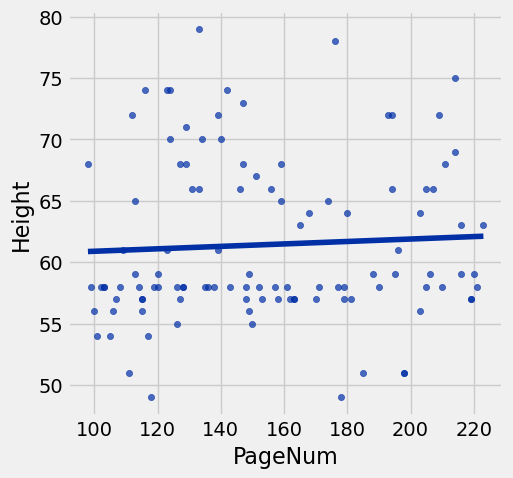

In [29]:
cars.scatter('PageNum', 'Height', fit_line=True)

Slope of regression line: 0.00997227190228
Approximate 95%-confidence interval for the true slope:
-0.0217626318122 0.0414766979853


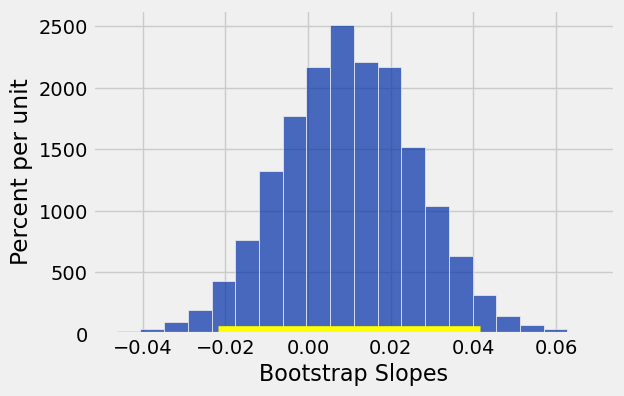

In [30]:
bootstrap_slope_simulation(cars, 'PageNum', 'Height', 5000)

We cannot reject the null hypothesis because 0 is within the 95% confidence interval. So the true slope for the linear relationship between page number and height is 0.

### Prediction Interval

We want to predict new data points that don't exist in our original sample set.

slope,intercept,age1=35,age2=65
0.622273,106.58,122.137,147.028
0.670882,103.473,120.245,147.08
0.689348,103.918,121.152,148.726
0.679208,104.226,121.206,148.375
0.623033,107.139,122.714,147.636
0.829806,94.0323,114.777,147.97
0.703765,102.054,119.648,147.798


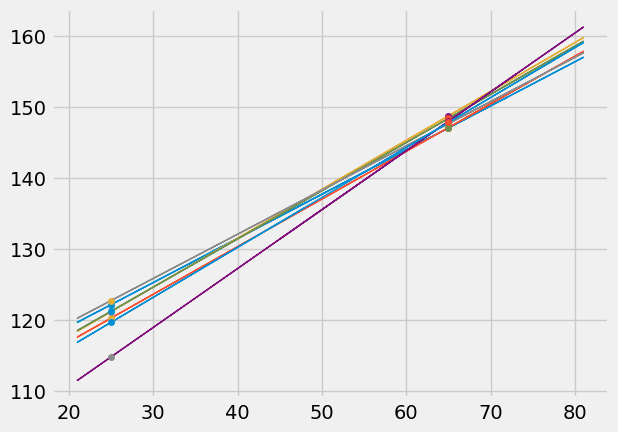

In [31]:
at_age_1 = 25
at_age_2 = 65

slopes = make_array()
intercepts = make_array()
predict_y_glucose_1 = make_array()
predict_y_glucose_2 = make_array()

for i in np.arange(7):
    bootstrap_sample = metabolic.sample()
    bootstrap_slope = slope(bootstrap_sample, 'age', 'glucose')
    bootstrap_intercept = intercept(bootstrap_sample, 'age', 'glucose')
    slopes = np.append(slopes, bootstrap_slope)
    intercepts = np.append(intercepts, bootstrap_intercept)
    fitted = fitted_values(bootstrap_sample, 'age', 'glucose')
    y_1 = prediction_at(bootstrap_sample, 'age', 'glucose', at_age_1);
    y_2 = prediction_at(bootstrap_sample, 'age', 'glucose', at_age_2);
    predict_y_glucose_1 = np.append(predict_y_glucose_1, y_1)
    predict_y_glucose_2 = np.append(predict_y_glucose_2, y_2)
    plots.plot(bootstrap_sample.column('age'), fitted, lw=1)
    
    plots.scatter(at_age_1, y_1, s=20, zorder=3);
    plots.scatter(at_age_2, y_2, s=20, zorder=3);

lines = Table().with_columns('slope', slopes, 
                             'intercept', intercepts, 
                             'age1=35', predict_y_glucose_1,
                             'age2=65', predict_y_glucose_2)
lines

In [32]:
# Bootstrap prediction of variable y at new_x
# Data contained in table; prediction by regression of y based on x
# repetitions = number of bootstrap replications of the original scatter plot

def fitted_value_at_x(table, x, y, given_x):
    a = slope(table, x, y)
    b = intercept(table, x, y)
    return a * given_x  + b
    
def bootstrap_prediction(table, x, y, new_x, repetitions):
    
    # For each repetition:
    # Bootstrap the scatter; 
    # get the regression prediction at new_x; 
    # augment the predictions list
    predictions = make_array()
    for i in np.arange(repetitions):
        bootstrap_sample = table.sample()
        bootstrap_prediction = prediction_at(bootstrap_sample, x, y, new_x)
        predictions = np.append(predictions, bootstrap_prediction)
        
    # Find the ends of the approximate 95% prediction interval
    left = percentile(2.5, predictions)
    right = percentile(97.5, predictions)
    
    # Prediction based on original sample
    original = prediction_at(table, x, y, new_x)
    
    # Display results
    Table().with_column('Prediction', predictions).hist(bins=20)
    plots.xlabel('predictions at x='+str(new_x))
    plots.plot(make_array(left, right), make_array(0, 0), color='yellow', lw=12);
    print('Height of regression line at x='+str(new_x)+':', original)
    print('Approximate 95%-confidence interval:')
    print(left, right)

Height of regression line at x=35: 125.991956148
Approximate 95%-confidence interval:
122.953327337 128.939729563


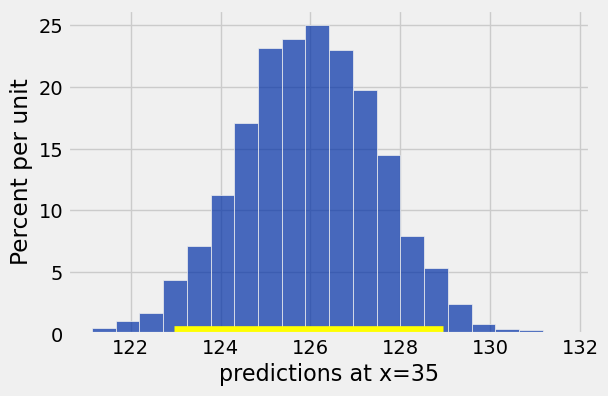

In [33]:
bootstrap_prediction(metabolic, 'age', 'glucose', 35, 5000)

Height of regression line at x=65: 147.688679363
Approximate 95%-confidence interval:
145.025401757 150.341983304


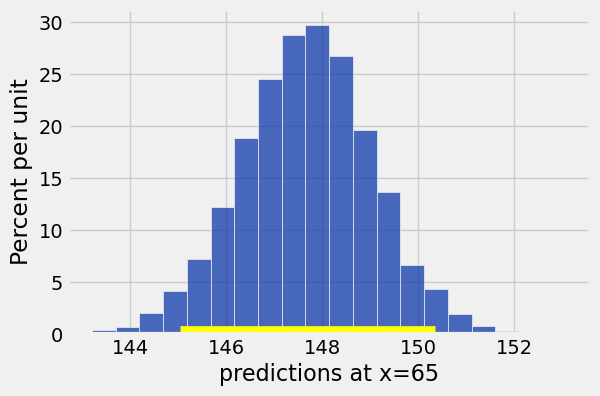

In [34]:
bootstrap_prediction(metabolic, 'age', 'glucose', 65, 5000)